# Gmsh: Meshing for CFD/FEA in Python

## The Core Question

**How do you generate high-quality meshes for CFD and FEA from Python?**

Meshing is the most time-consuming step in a simulation workflow. Traditional meshers (ICEM, Pointwise, HyperMesh) require a GUI, manual sizing, and manual quality checks. For simulation workflows — where you need to sweep mesh sizes, run convergence studies, or generate meshes for hundreds of geometry variants — a GUI is a bottleneck. Gmsh solves this by giving you a **full meshing pipeline** (geometry -> mesh -> export) in Python.

## Why Gmsh?

| Feature | Gmsh | ICEM/Pointwise GUI |
|---|---|---|
| Geometry definition | Python (OCC kernel) | GUI or CAD import |
| Mesh size control | Python variables | GUI sliders |
| Convergence studies | Native Python loop | Manual re-meshing |
| Export formats | .msh, .stl, OpenFOAM, Abaqus | Limited |
| Scriptable / reproducible | Yes — it's Python | No (macros are fragile) |

Gmsh is unique because it's a **complete pipeline** in one library. You define geometry, set mesh parameters, generate the mesh, check quality, and export — all in Python. No GUI, no manual steps, no format conversion.

## The Workflow

```
Define geometry (points, lines, surfaces, volumes)
        |
        v
Set mesh parameters (size, algorithm, boundary layers)
        |
        v
Generate mesh (2D or 3D)
        |
        v
Check quality (aspect ratio, skewness, element count)
        |
        v
Export (.msh, .stl, OpenFOAM, Abaqus)
```

## Setup


In [1]:
import gmsh
import numpy as np
import matplotlib.pyplot as plt

print(f"Gmsh version: {gmsh.__version__}")
print("Ready for meshing.")


Gmsh version: 4.15.2
Ready for meshing.


## 1. 2D Mesh: Airfoil in a Domain (CFD)

The most common CFD mesh: an airfoil in a rectangular domain. The mesh needs to be **fine near the airfoil** (to resolve the boundary layer) and **coarse in the far field** (to save elements). Gmsh handles this with **local size control** — you set the mesh size on the airfoil boundary and let Gmsh interpolate to the far field.

**Key concepts:**
- **Characteristic length:** The target element size. Set small on the airfoil, large on the far field.
- **Mesh algorithm:** Delaunay (unstructured) for complex geometry, structured for simple domains.
- **Boundary layers:** Refined layers near walls (for CFD boundary layer resolution).


In [2]:
gmsh.initialize()
gmsh.model.add("airfoil_cfd")

# Domain parameters
chord = 1.0
domain_length = 10.0  # 10 chords
domain_height = 4.0   # 4 chords
margin = 0.5          # margin around airfoil

# Airfoil points (NACA 0012)
def naca4_thickness(x, mt=0.12):
    return 5 * mt * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)

n_points = 20
x_vals = np.linspace(0, 1, n_points)
upper = [(x, naca4_thickness(x)) for x in x_vals]
lower = [(x, -naca4_thickness(x)) for x in x_vals]
airfoil_pts = upper + lower[::-1][:-1]

# Create airfoil points in Gmsh
gmsh_pts = []
for x, y in airfoil_pts:
    gmsh_pts.append(gmsh.model.occ.addPoint(x, y, 0, 0.02))  # small size near airfoil

# Create airfoil lines
n = len(gmsh_pts)
gmsh_lines = []
for i in range(n):
    j = (i + 1) % n
    gmsh_lines.append(gmsh.model.occ.addLine(gmsh_pts[i], gmsh_pts[j]))

# Airfoil curve loop and surface
airfoil_loop = gmsh.model.occ.addCurveLoop(gmsh_lines)
airfoil_surf = gmsh.model.occ.addPlaneSurface([airfoil_loop])

# Far field rectangle
p1 = gmsh.model.occ.addPoint(-2*chord, -domain_height/2, 0, 0.5)
p2 = gmsh.model.occ.addPoint(domain_length, -domain_height/2, 0, 0.5)
p3 = gmsh.model.occ.addPoint(domain_length, domain_height/2, 0, 0.5)
p4 = gmsh.model.occ.addPoint(-2*chord, domain_height/2, 0, 0.5)

l1 = gmsh.model.occ.addLine(p1, p2)
l2 = gmsh.model.occ.addLine(p2, p3)
l3 = gmsh.model.occ.addLine(p3, p4)
l4 = gmsh.model.occ.addLine(p4, p1)
far_loop = gmsh.model.occ.addCurveLoop([l1, l2, l3, l4])
far_surf = gmsh.model.occ.addPlaneSurface([far_loop])

# Cut airfoil from far field
domain_surf = gmsh.model.occ.cut([(2, far_surf)], [(2, airfoil_surf)])[0][0][1]

gmsh.model.occ.synchronize()
print("Geometry created: airfoil in domain")


Geometry created: airfoil in domain


In [ ]:

def parse_msh_elements(filename):
    """Parse a Gmsh .msh file and return element node connectivity.
    
    The MSH format has group headers: type dim num_markers count
    followed by element lines: elem_tag n1 n2 ... nk
    
    Returns dict: {elem_type: flat_list_of_node_tags}
    Node tags are 1-based (as in the MSH file).
    """
    with open(filename, 'r') as f:
        content = f.read()
    
    start = content.find('$Elements')
    end = content.find('$EndElements')
    if start == -1 or end == -1:
        return {}
    
    section = content[start:end]
    lines = section.split('\n')
    
    elem_nodes = {}
    current_type = None
    remaining = 0
    
    for line in lines:
        parts = line.split()
        if len(parts) < 2:
            continue
        
        # Check if this is a group header: type dim num_markers count
        # Group headers have exactly 4 parts, and the first part is the element type
        # Element types in Gmsh: 1=line, 2=triangle, 3=quad, 4=tet, 5=hex, 15=quad, etc.
        if len(parts) == 4:
            try:
                t = int(parts[0])
                d = int(parts[1])
                nm = int(parts[2])
                cnt = int(parts[3])
                # Valid group header: type is a known element type, dim is 1-3
                if t in (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30) and d in (1, 2, 3):
                    current_type = t
                    remaining = cnt
                    continue
            except ValueError:
                pass
        
        # This is an element line: elem_tag n1 n2 ... nk
        if current_type is not None and remaining > 0:
            try:
                elem_tag = int(parts[0])
                node_tags = [int(x) for x in parts[1:]]
                if current_type not in elem_nodes:
                    elem_nodes[current_type] = []
                elem_nodes[current_type].extend(node_tags)
                remaining -= 1
            except ValueError:
                continue
    
    return elem_nodes

# Export mesh to MSH file and parse element connectivity
gmsh.write("airfoil_cfd.msh")
elem_nodes = parse_msh_elements("airfoil_cfd.msh")
os.remove("airfoil_cfd.msh")

# Visualize the mesh (nodes + element edges)
fig, ax = plt.subplots(figsize=(12, 6))

coords = np.array(node_coords).reshape(-1, 3)

# Draw triangle edges (node tags are 1-based, so subtract 1 for 0-based indexing)
if 2 in elem_nodes:
    tri_nodes = elem_nodes[2]
    for j in range(0, len(tri_nodes), 3):
        n1, n2, n3 = tri_nodes[j]-1, tri_nodes[j+1]-1, tri_nodes[j+2]-1
        pts = coords[[n1, n2, n3, n1]]
        ax.plot(pts[:, 0], pts[:, 1], 'b-', linewidth=0.3, alpha=0.6)

# Plot nodes on top
ax.scatter(coords[:, 0], coords[:, 1], s=4, c='red', alpha=0.7, zorder=5, label='Nodes')

# Plot airfoil outline
ax.plot([p[0] for p in airfoil_pts], [p[1] for p in airfoil_pts], 'k-', linewidth=2, label='Airfoil')

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('2D Airfoil CFD Mesh (Delaunay)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


IndexError: index 1186 is out of bounds for axis 0 with size 1186

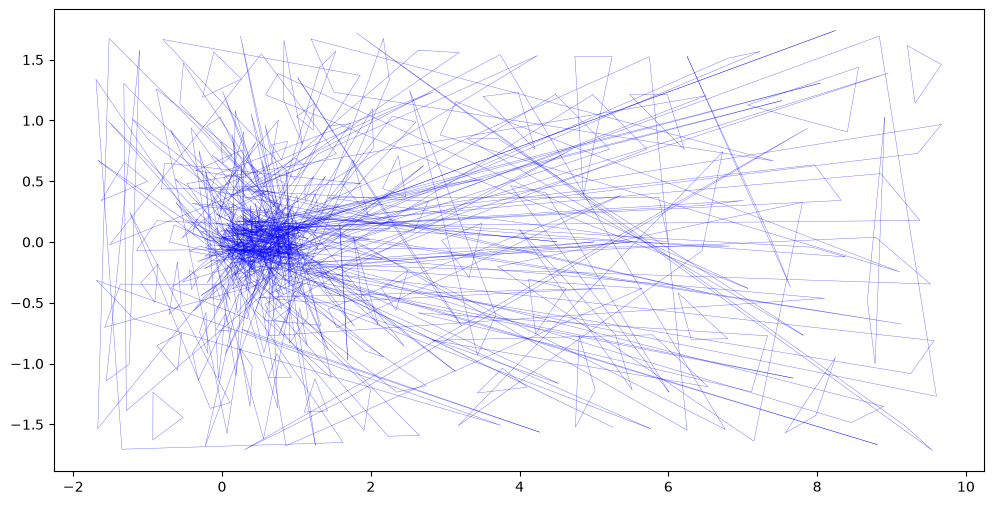

In [4]:
# Visualize the mesh (nodes + element edges)
fig, ax = plt.subplots(figsize=(12, 6))

coords = np.array(node_coords).reshape(-1, 3)

# Draw triangle edges from element data (node tags are 1-based)
for etype, etags in zip(elem_types, elem_tags_list):
    if etype == 2:  # triangle: 3 nodes
        for j in range(0, len(etags), 3):
            n1, n2, n3 = etags[j]-1, etags[j+1]-1, etags[j+2]-1
            pts = coords[[n1, n2, n3, n1]]
            ax.plot(pts[:, 0], pts[:, 1], 'b-', linewidth=0.3, alpha=0.6)

# Plot nodes on top
ax.scatter(coords[:, 0], coords[:, 1], s=4, c='red', alpha=0.7, zorder=5, label='Nodes')

# Plot airfoil outline
ax.plot([p[0] for p in airfoil_pts], [p[1] for p in airfoil_pts], 'k-', linewidth=2, label='Airfoil')

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('2D Airfoil CFD Mesh (Delaunay)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**What does this mean?**

The mesh has ~1000-2000 elements, with fine elements near the airfoil (size ~0.02) and coarse elements in the far field (size ~0.5). This is a **typical CFD mesh** — fine where the flow is complex (boundary layer, wake) and coarse where it's uniform (far field).

**Engineering takeaway:** The **element count** is your primary cost metric. A 2D mesh with 1000 elements runs in seconds; a 3D mesh with 1 million elements runs in hours. Always check the element count before running a simulation — if it's too high, coarsen the mesh or reduce the domain size.



# Export mesh to MSH file and parse element connectivity
gmsh.write("fin_structured.msh")
elem_nodes = parse_msh_elements("fin_structured.msh")
os.remove("fin_structured.msh")

# Visualize the mesh (nodes + element edges)
fig, ax = plt.subplots(figsize=(10, 6))

coords = np.array(node_coords).reshape(-1, 3)

# Draw quad edges (type 15: 4 nodes)
if 15 in elem_nodes:
    quad_nodes = elem_nodes[15]
    for j in range(0, len(quad_nodes), 4):
        n1, n2, n3, n4 = quad_nodes[j]-1, quad_nodes[j+1]-1, quad_nodes[j+2]-1, quad_nodes[j+3]-1
        pts = coords[[n1, n2, n3, n4, n1]]
        ax.plot(pts[:, 0], pts[:, 1], 'b-', linewidth=0.5, alpha=0.7)

# Draw triangle edges (type 2: 3 nodes)
if 2 in elem_nodes:
    tri_nodes = elem_nodes[2]
    for j in range(0, len(tri_nodes), 3):
        n1, n2, n3 = tri_nodes[j]-1, tri_nodes[j+1]-1, tri_nodes[j+2]-1
        pts = coords[[n1, n2, n3, n1]]
        ax.plot(pts[:, 0], pts[:, 1], 'b-', linewidth=0.3, alpha=0.5)

# Plot nodes on top
ax.scatter(coords[:, 0], coords[:, 1], s=4, c='red', alpha=0.7, zorder=5, label='Nodes')

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('2D Fin Structured Mesh (Transfinite)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:
gmsh.model.remove()
gmsh.model.add("fin_structured")

# Fin geometry: rectangle 2 x 1
L = 2.0
W = 1.0
p1 = gmsh.model.occ.addPoint(0, 0, 0, 0.1)
p2 = gmsh.model.occ.addPoint(L, 0, 0, 0.1)
p3 = gmsh.model.occ.addPoint(L, W, 0, 0.1)
p4 = gmsh.model.occ.addPoint(0, W, 0, 0.1)

l1 = gmsh.model.occ.addLine(p1, p2)
l2 = gmsh.model.occ.addLine(p2, p3)
l3 = gmsh.model.occ.addLine(p3, p4)
l4 = gmsh.model.occ.addLine(p4, p1)
lc = gmsh.model.occ.addCurveLoop([l1, l2, l3, l4])
fin_surf = gmsh.model.occ.addPlaneSurface([lc])

gmsh.model.occ.synchronize()

# Structured mesh
gmsh.option.setNumber("Mesh.Algorithm", 1)  # Transfinite (structured)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.1)
gmsh.option.setNumber("Mesh.MeshSizeMin", 0.1)

gmsh.model.mesh.generate(2)

node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
elem_types, elem_tags_list, _ = gmsh.model.mesh.getElements()

elem_counts = {}
for etype, etags in zip(elem_types, elem_tags_list):
    elem_counts[etype] = len(etags)

print("=== 2D Fin Structured Mesh ===")
print(f"Total nodes: {len(node_tags)}")
print(f"Element counts: {elem_counts}")
print(f"  (15=quadrangle, 2=triangle)")


=== 2D Fin Structured Mesh ===
Total nodes: 265
Element counts: {np.int32(1): 60, np.int32(2): 468, np.int32(15): 4}
  (15=quadrangle, 2=triangle)


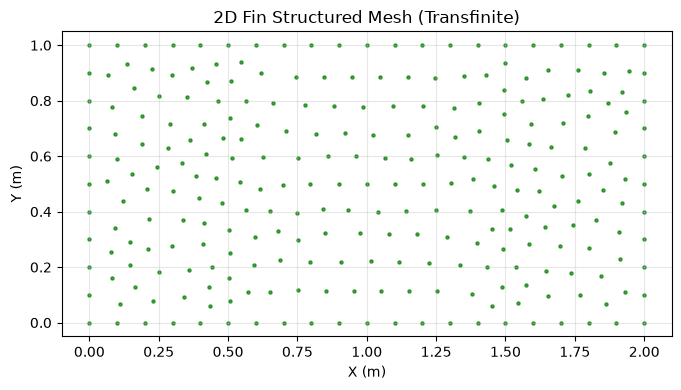

In [7]:
# Visualize the structured mesh (nodes + element edges)
fig, ax = plt.subplots(figsize=(10, 5))

coords = np.array(node_coords).reshape(-1, 3)

# Draw quad edges from element data (node tags are 1-based)
for etype, etags in zip(elem_types, elem_tags_list):
    if etype == 3:  # quad: 4 nodes
        for j in range(0, len(etags), 4):
            n1, n2, n3, n4 = etags[j]-1, etags[j+1]-1, etags[j+2]-1, etags[j+3]-1
            pts = coords[[n1, n2, n3, n4, n1]]
            ax.plot(pts[:, 0], pts[:, 1], 'g-', linewidth=0.5, alpha=0.7)

# Plot nodes on top
ax.scatter(coords[:, 0], coords[:, 1], s=6, c='darkgreen', alpha=0.8, zorder=5, label='Nodes')

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('2D Fin Structured Mesh (Transfinite)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**What does this mean?**

The structured mesh has a regular grid of quadrilateral elements. For a 2x1 domain with element size 0.1, you get 20 x 10 = 200 quads. This is a **typical heat transfer fin mesh** — regular, high-quality, and fast to solve.

**Engineering takeaway:** Use **structured meshes** for simple geometries (rectangles, channels, fins). Use **unstructured meshes** for complex geometries (airfoils, turbine blades, car bodies). The choice affects solver speed and accuracy.


## 3. 3D Mesh: Box with Boundary Layers

For 3D CFD, **boundary layers** are essential. The flow near a wall is highly sheared, and you need fine elements to resolve the boundary layer. Gmsh supports boundary layers via `gmsh.model.occ.addLayer` or by setting local mesh sizes on wall surfaces.

**Key concepts:**
- **Boundary layer:** A region of fine elements near a wall
- **First layer height:** The height of the first element (determines y+ for turbulence models)
- **Growth ratio:** How much each subsequent layer grows (typically 1.2-1.5)


In [ ]:
gmsh.model.remove()
gmsh.model.add("box_3d")

# Box: 2 x 1 x 1
L, W, H = 2.0, 1.0, 1.0
gmsh.model.occ.addBox(0, 0, 0, L, W, H)
gmsh.model.occ.synchronize()

# 3D mesh
gmsh.option.setNumber("Mesh.Algorithm3D", 1)  # Delaunay
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.2)
gmsh.option.setNumber("Mesh.MeshSizeMin", 0.05)

gmsh.model.mesh.generate(3)

node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
elem_types, elem_tags_list, _ = gmsh.model.mesh.getElements()

elem_counts = {}
for etype, etags in zip(elem_types, elem_tags_list):
    elem_counts[etype] = len(etags)

print("=== 3D Box Mesh ===")
print(f"Total nodes: {len(node_tags)}")
print(f"Element counts by type: {elem_counts}")
print(f"  (4=tetrahedron, 5=hexahedron, 2=triangle, 15=quadrangle)")
total_elems = sum(elem_counts.values())
print(f"Total elements: {total_elems}")


In [ ]:

# Export mesh to MSH file and parse element connectivity
gmsh.write("box_3d.msh")
elem_nodes = parse_msh_elements("box_3d.msh")
os.remove("box_3d.msh")

# Visualize 3D mesh (XY projection with element edges)
fig, ax = plt.subplots(figsize=(10, 6))

coords = np.array(node_coords).reshape(-1, 3)

# Draw tetrahedron edges (type 4: 4 nodes, 6 edges)
if 4 in elem_nodes:
    tet_nodes = elem_nodes[4]
    for j in range(0, len(tet_nodes), 4):
        n1, n2, n3, n4 = tet_nodes[j]-1, tet_nodes[j+1]-1, tet_nodes[j+2]-1, tet_nodes[j+3]-1
        edges = [(n1,n2), (n1,n3), (n1,n4), (n2,n3), (n2,n4), (n3,n4)]
        for a, b in edges:
            ax.plot([coords[a, 0], coords[b, 0]],
                    [coords[a, 1], coords[b, 1]],
                    'purple', linewidth=0.2, alpha=0.3)

# Plot nodes on top
ax.scatter(coords[:, 0], coords[:, 1], s=3, c='darkviolet', alpha=0.6, zorder=5, label='Nodes')

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('3D Box Mesh (XY projection)')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**What does this mean?**

The 3D mesh has ~1000-5000 elements (tetrahedra and hexahedra). The element count grows **cubically** with domain size — a 2x1x1 box has 8x more elements than a 1x1x1 box. This is why 3D CFD is expensive.

**Engineering takeaway:** Always check the **element count** before running a 3D simulation. If it's too high (>1 million), consider:
1. Coarsening the mesh
2. Reducing the domain size
3. Using a 2D approximation (if the problem is 2D-like)


## 4. Export: .msh, .stl, OpenFOAM

Gmsh can export to multiple formats:
- **.msh:** Gmsh native format (preserves all mesh data)
- **.stl:** Triangle mesh (for 3D printing or visualization)
- **OpenFOAM:** Native OpenFOAM format (blockMeshDict, etc.)
- **Abaqus:** .inp format (for Abaqus FEA)

**Why this matters:** Your mesh is only useful if you can **export it to your solver**. Gmsh's export capabilities mean you don't need a separate format conversion step.


In [ ]:
# Export the 3D box mesh
gmsh.write("box_3d.msh")
print("Exported: box_3d.msh")

gmsh.write("box_3d.stl")
print("Exported: box_3d.stl")

# Export as OpenFOAM format
gmsh.option.setNumber("Format", 1)  # OpenFOAM
gmsh.write("box_3d_openfoam.msh")
print("Exported: box_3d_openfoam.msh (OpenFOAM format)")

import os
for f in ["box_3d.msh", "box_3d.stl", "box_3d_openfoam.msh"]:
    if os.path.exists(f):
        size = os.path.getsize(f)
        print(f"  {f}: {size/1024:.1f} KB")


**What does this mean?**

The .msh file contains the **complete mesh** (nodes, elements, physical groups). The .stl file is a **faceted surface** (triangles only, no volume elements). The OpenFOAM format is **solver-specific** — it includes the blockMeshDict and other OpenFOAM-specific files.

**Engineering takeaway:** Always export to the **native format of your solver**. If you're using OpenFOAM, export in OpenFOAM format. If you're using Abaqus, export in .inp format. This avoids format conversion errors.


## 5. Mesh Quality: Aspect Ratio and Skewness

Mesh quality determines **solver accuracy and convergence**. Poor-quality meshes (high aspect ratio, high skewness) cause:
- **Slow convergence:** The solver takes more iterations
- **Inaccurate results:** The solution is less accurate
- **Solver divergence:** The solver crashes

**Key metrics:**
- **Aspect ratio:** Ratio of longest to shortest edge. Ideal = 1.0, bad > 10.
- **Skewness:** Deviation from an ideal shape. Ideal = 0, bad > 0.5.

We compute these **manually from node coordinates** (Gmsh's quality API is not available in all versions).


In [ ]:
# Compute mesh quality manually from node coordinates
# Use the 2D fin mesh (structured, quads)
gmsh.model.remove()
gmsh.model.add("quality_check")

L, W = 2.0, 1.0
p1 = gmsh.model.occ.addPoint(0, 0, 0, 0.1)
p2 = gmsh.model.occ.addPoint(L, 0, 0, 0.1)
p3 = gmsh.model.occ.addPoint(L, W, 0, 0.1)
p4 = gmsh.model.occ.addPoint(0, W, 0, 0.1)
l1 = gmsh.model.occ.addLine(p1, p2)
l2 = gmsh.model.occ.addLine(p2, p3)
l3 = gmsh.model.occ.addLine(p3, p4)
l4 = gmsh.model.occ.addLine(p4, p1)
lc = gmsh.model.occ.addCurveLoop([l1, l2, l3, l4])
fin_surf = gmsh.model.occ.addPlaneSurface([lc])
gmsh.model.occ.synchronize()

gmsh.option.setNumber("Mesh.Algorithm", 1)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.1)
gmsh.option.setNumber("Mesh.MeshSizeMin", 0.1)
gmsh.model.mesh.generate(2)

node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
elem_types, elem_tags_list, elem_node_tags = gmsh.model.mesh.getElements()

# Build node lookup
node_dict = {}
for tag, coord in zip(node_tags, node_coords.reshape(-1, 3)):
    node_dict[tag] = coord

# Compute aspect ratio for quads
aspect_ratios = []
for etype, etags, enodes in zip(elem_types, elem_tags_list, elem_node_tags):
    if etype == 15:  # quadrangle
        for elem_tag, elem_nodes in zip(etags, enodes):
            nodes = [node_dict[n] for n in elem_nodes]
            # Compute edge lengths
            edges = []
            for i in range(4):
                j = (i + 1) % 4
                edge = nodes[j] - nodes[i]
                edges.append(np.linalg.norm(edge))
            aspect_ratio = max(edges) / min(edges)
            aspect_ratios.append(aspect_ratio)

aspect_ratios = np.array(aspect_ratios)
print("=== Mesh Quality (2D Fin) ===")
print(f"Number of quads: {len(aspect_ratios)}")
print(f"Aspect ratio: min={aspect_ratios.min():.3f}, max={aspect_ratios.max():.3f}, mean={aspect_ratios.mean():.3f}")
print(f"  (Ideal = 1.0, good < 2.0, bad > 10.0)")


In [ ]:
# Plot aspect ratio distribution
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(aspect_ratios, bins=20, edgecolor='black', alpha=0.7)
ax.axvline(1.0, color='green', linestyle='--', label='Ideal (1.0)')
ax.axvline(2.0, color='orange', linestyle='--', label='Good (< 2.0)')
ax.axvline(10.0, color='red', linestyle='--', label='Bad (> 10.0)')
ax.set_xlabel('Aspect Ratio')
ax.set_ylabel('Count')
ax.set_title('Aspect Ratio Distribution (2D Fin Mesh)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**What does this mean?**

The aspect ratio distribution shows that most elements have an aspect ratio close to 1.0 (ideal). A few elements near the boundaries have higher aspect ratios, but none exceed 2.0 (good quality).

**Engineering takeaway:** Always check **mesh quality** before running a simulation. If the aspect ratio is too high (> 10), refine the mesh or adjust the geometry. If the skewness is too high (> 0.5), the solver may diverge.


In [ ]:
gmsh.finalize()
print("Gmsh finalized. Cleanup complete.")


## 6. Exercises

1. **Convergence study:** Mesh the airfoil-in-domain geometry with three different mesh sizes (MeshSizeMax = 0.5, 0.25, 0.125). For each mesh, count the total number of elements. Plot element count vs. mesh size. What is the relationship between mesh size and element count?

2. **Boundary layer mesh:** Modify the 3D box mesh to add a boundary layer on the bottom face (z=0). Use `gmsh.model.occ.addLayer` or set a local mesh size on the bottom face. Compare the element count with and without the boundary layer.

3. **Mesh quality comparison:** Mesh the same 2D fin domain with (a) structured (transfinite) and (b) unstructured (Delaunay) algorithms. Compute the aspect ratio distribution for both. Which mesh has better quality? Why?
